<a href="https://colab.research.google.com/github/razokiyassine/Network-Intrusion-Detection/blob/main/tp2-instrusion2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [48]:
df = pd.read_csv("Train_data.csv")
print("Dimensions :", df.shape)
print(df.head())
print(df['class'].value_counts())

Dimensions : (25192, 42)
   duration protocol_type   service flag  src_bytes  dst_bytes  land  \
0         0           tcp  ftp_data   SF        491          0     0   
1         0           udp     other   SF        146          0     0   
2         0           tcp   private   S0          0          0     0   
3         0           tcp      http   SF        232       8153     0   
4         0           tcp      http   SF        199        420     0   

   wrong_fragment  urgent  hot  ...  dst_host_srv_count  \
0               0       0    0  ...                  25   
1               0       0    0  ...                   1   
2               0       0    0  ...                  26   
3               0       0    0  ...                 255   
4               0       0    0  ...                 255   

   dst_host_same_srv_rate  dst_host_diff_srv_rate  \
0                    0.17                    0.03   
1                    0.00                    0.60   
2                    0.10   

In [49]:
# protocol_type, service, flag sont du texte -> il faut les transformer en nombres
cat_cols = ["protocol_type", "service", "flag"]
df_encoded = df.copy()

for col in cat_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])

# La cible : normal -> 0, anomaly -> 1
df_encoded["class"] = df_encoded["class"].map({"normal": 0, "anomaly": 1})

print(df_encoded[cat_cols + ["class"]].head())

   protocol_type  service  flag  class
0              1       19     9      0
1              2       41     9      0
2              1       46     5      1
3              1       22     9      0
4              1       22     9      0


In [50]:
X = df_encoded.drop(columns=["class"])
y = df_encoded["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (20153, 41)
Test : (5039, 41)


In [51]:
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)
print("Modèle entraîné !")

Modèle entraîné !


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [52]:
y_pred = model.predict(X_test)
print("Prédictions :   ", y_pred[:10])
print("Valeurs réelles :", y_test.to_numpy()[:10])

Prédictions :    [0 1 1 0 1 0 1 1 0 0]
Valeurs réelles : [0 1 1 1 1 0 1 1 0 0]


In [53]:
acc = accuracy_score(y_test, y_pred)
print("Accuracy :", round(acc * 100, 2), "%")
print()
print(classification_report(y_test, y_pred, target_names=["normal", "anomaly"]))

Accuracy : 90.04 %

              precision    recall  f1-score   support

      normal       0.86      0.97      0.91      2690
     anomaly       0.96      0.82      0.88      2349

    accuracy                           0.90      5039
   macro avg       0.91      0.90      0.90      5039
weighted avg       0.91      0.90      0.90      5039



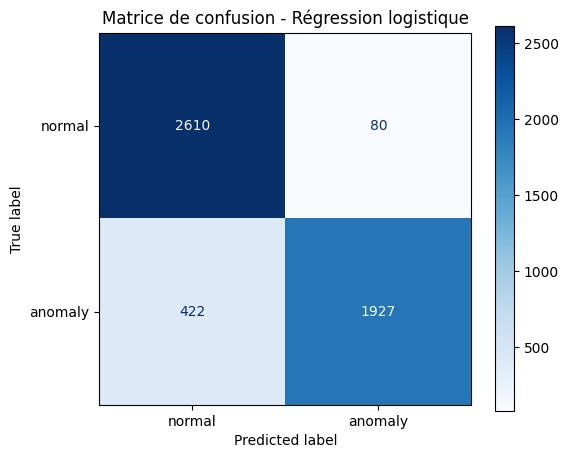

In [54]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["normal", "anomaly"])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Matrice de confusion - Régression logistique")
plt.show()

In [55]:
# Exemple : on prend une ligne du test set et on vérifie la prédiction
sample = X_test.iloc[[0]]
prediction = model.predict(sample)
print("ALERTE : anomaly" if prediction[0] == 1 else "Normale")
print("Vraie valeur :", "anomaly" if y_test.iloc[0] == 1 else "normal")

Normale
Vraie valeur : normal
